## 1. Данные из задания 4

In [1]:
from pathlib import Path
from time import perf_counter, perf_counter_ns
import json
import faiss
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

faiss.omp_set_num_threads(1)
DATA = Path("/home/jovyan/task4_data")
EXPORT = DATA / "vector_search"
chunks = pd.read_json(EXPORT / "chunks.json")
corpus = pd.read_json(DATA / "corpus.json")
queries = json.loads((EXPORT / "queries.json").read_text(encoding="utf-8"))
x = np.ascontiguousarray(np.load(EXPORT / "document_vectors.npy"), dtype=np.float32)
q = np.ascontiguousarray(np.load(EXPORT / "query_vectors.npy"), dtype=np.float32)
faiss.normalize_L2(x)
faiss.normalize_L2(q)
k = 10
assert len(x) == len(chunks) and len(q) == len(queries)
print("Документы:", chunks.doc_id.nunique(), "чанки:", len(x), "размерность:", x.shape[1])
display(chunks.head(3).merge(corpus[["doc_id", "title"]], on="doc_id"))


Документы: 121 чанки: 2003 размерность: 384


,chunk_id,doc_id,text,title
0,0,concepts/budget,Управление расходами\nСуществует несколько спо...,Управление расходами
1,1,concepts/budget,Управление расходами\nможете настроить пороги ...,Управление расходами
2,2,concepts/budget,Управление расходами\nбаланс на то количество ...,Управление расходами


## 2. Точный поиск

In [2]:
start = perf_counter()
flat = faiss.IndexFlatIP(x.shape[1])
flat.add(x)
flat_build_seconds = perf_counter() - start
exact_scores, exact_ids = flat.search(q, k)
assert np.allclose(exact_scores[0], np.sort(q[0] @ x.T)[-k:][::-1], atol=1e-6)

def show_search(query_index, indices, scores):
    rows = chunks.iloc[indices[query_index]].copy()
    rows.insert(0, "rank", np.arange(1, len(rows) + 1))
    rows["score"] = scores[query_index]
    rows["relevant"] = rows.doc_id.isin(queries[query_index]["relevant"])
    print(queries[query_index]["query"])
    display(rows.merge(corpus[["doc_id", "title"]], on="doc_id")[["rank", "title", "score", "relevant"]])

show_search(0, exact_ids, exact_scores)


Как записать загрузку GPU в файл во время обучения через nvidia-smi?


,rank,title,score,relevant
0,1,Проверить загрузку GPU,0.921893,True
1,2,Проверить загрузку GPU,0.907114,True
2,3,Проверить загрузку GPU,0.899537,True
3,4,Проверить загрузку GPU,0.894306,True
4,5,Проверить загрузку GPU,0.892104,True
5,6,Проверить загрузку GPU,0.889678,True
6,7,Проверить загрузку GPU,0.877864,True
7,8,Проверить загрузку GPU,0.866123,True
8,9,Проверить загрузку GPU,0.865350,True
9,10,Среда исполнения заданий,0.864341,False


## 3. Метрики и измерение времени

In [3]:
def ann_recall(found, expected):
    return np.array([len(set(a[a >= 0]) & set(b)) / k for a, b in zip(found, expected)])

def document_metrics(found):
    recalls, hits = [], []
    for query, ids in zip(queries, found):
        retrieved = set(chunks.iloc[ids[ids >= 0]].doc_id)
        relevant = set(query["relevant"])
        count = len(retrieved & relevant)
        recalls.append(count / len(relevant))
        hits.append(count > 0)
    return np.mean(recalls), np.mean(hits)

def measure_search(index, vectors=q, repeats=100):
    for row in vectors:
        index.search(row[None], k)
    times = []
    for _ in range(repeats):
        for row in vectors:
            start = perf_counter_ns()
            index.search(row[None], k)
            times.append((perf_counter_ns() - start) / 1e6)
    return dict(mean_ms=np.mean(times), p95_ms=np.percentile(times, 95))

assert np.all(ann_recall(exact_ids, exact_ids) == 1)
assert ann_recall(np.arange(10)[None], np.arange(5, 15)[None])[0] == 0.5
flat_time = measure_search(flat)
print("Точный поиск:", flat_time)
print("Recall документов, Hit rate:", document_metrics(exact_ids))


Точный поиск: {'mean_ms': np.float64(0.06185871833333333), 'p95_ms': np.float64(0.07550499999999999)}
Recall документов, Hit rate: (np.float64(0.657638888888889), np.float64(0.875))


## 4. HNSW: исходный эксперимент

In [4]:
start = perf_counter()
hnsw = faiss.IndexHNSWFlat(x.shape[1], 16, faiss.METRIC_INNER_PRODUCT)
hnsw.hnsw.efConstruction = 200
hnsw.hnsw.efSearch = 10
hnsw.add(x)
hnsw_build_seconds = perf_counter() - start
hnsw_scores, hnsw_ids = hnsw.search(q, k)
print("Построение, с:", hnsw_build_seconds)
print("ANN Recall@10:", ann_recall(hnsw_ids, exact_ids).mean())
print("Поиск:", measure_search(hnsw))
show_search(0, hnsw_ids, hnsw_scores)


Построение, с: 0.20562874999995984
ANN Recall@10: 0.8458333333333332
Поиск: {'mean_ms': np.float64(0.013636617083333332), 'p95_ms': np.float64(0.01652)}
Как записать загрузку GPU в файл во время обучения через nvidia-smi?


,rank,title,score,relevant
0,1,Проверить загрузку GPU,0.921893,True
1,2,Проверить загрузку GPU,0.907114,True
2,3,Проверить загрузку GPU,0.899537,True
3,4,Проверить загрузку GPU,0.894306,True
4,5,Проверить загрузку GPU,0.892104,True
5,6,Проверить загрузку GPU,0.889678,True
6,7,Проверить загрузку GPU,0.877864,True
7,8,Проверить загрузку GPU,0.866123,True
8,9,Проверить загрузку GPU,0.865350,True
9,10,Среда исполнения заданий,0.864341,False


## 5. Подбор efSearch

,efSearch,recall,mean_ms,p95_ms
0,10,0.8458,0.0135,0.0163
1,16,0.8833,0.0174,0.0211
8,17,0.8958,0.0186,0.0226
9,18,0.9042,0.0197,0.0242
10,19,0.9042,0.0200,0.0237
11,20,0.9167,0.0209,0.0285
12,21,0.9167,0.0216,0.0255
13,22,0.9250,0.0218,0.0263
14,23,0.9333,0.0226,0.0288
2,24,0.9625,0.0239,0.0325


Минимальное проверенное efSearch: 24


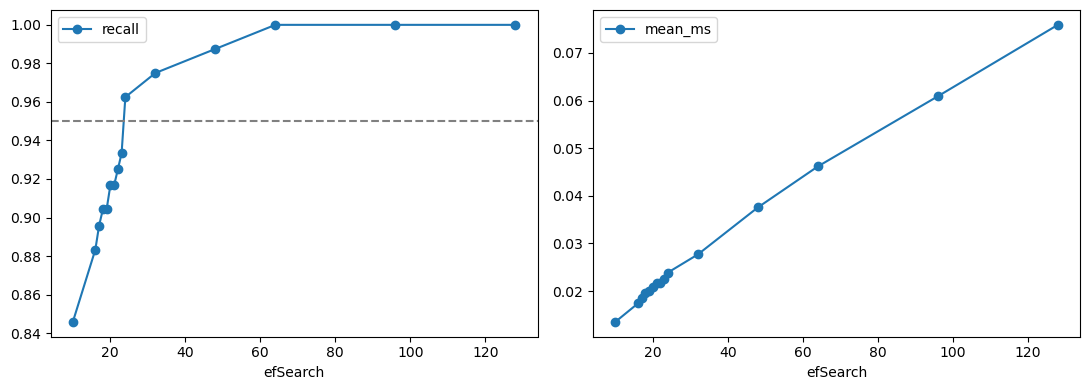

In [5]:
hnsw_results = []
for ef in [10, 16, 24, 32, 48, 64, 96, 128]:
    hnsw.hnsw.efSearch = ef
    scores, ids = hnsw.search(q, k)
    hnsw_results.append(dict(efSearch=ef, recall=ann_recall(ids, exact_ids).mean(), **measure_search(hnsw)))
hnsw_table = pd.DataFrame(hnsw_results)
passing = hnsw_table.loc[hnsw_table.recall >= 0.95]
assert not passing.empty
upper = int(passing.efSearch.min())
lower = max([ef for ef in hnsw_table.efSearch if ef < upper], default=9)
for ef in range(lower + 1, upper):
    hnsw.hnsw.efSearch = ef
    _, ids = hnsw.search(q, k)
    hnsw_results.append(dict(efSearch=ef, recall=ann_recall(ids, exact_ids).mean(), **measure_search(hnsw)))
hnsw_table = pd.DataFrame(hnsw_results).sort_values("efSearch")
best_ef = int(hnsw_table.loc[hnsw_table.recall >= 0.95, "efSearch"].min())
hnsw.hnsw.efSearch = best_ef
hnsw_scores, hnsw_ids = hnsw.search(q, k)
display(hnsw_table.round(4))
print("Минимальное проверенное efSearch:", best_ef)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
hnsw_table.plot(x="efSearch", y="recall", marker="o", ax=axes[0])
axes[0].axhline(0.95, linestyle="--", color="gray")
hnsw_table.plot(x="efSearch", y="mean_ms", marker="o", ax=axes[1])
plt.tight_layout()
plt.show()


## 6. IVF: исходный эксперимент

In [6]:
start = perf_counter()
ivf = faiss.IndexIVFFlat(faiss.IndexFlatIP(x.shape[1]), x.shape[1], 32, faiss.METRIC_INNER_PRODUCT)
ivf.cp.seed = 42
ivf.train(x)
ivf.add(x)
ivf.nprobe = 1
ivf_build_seconds = perf_counter() - start
ivf_scores, ivf_ids = ivf.search(q, k)
print("Построение, с:", ivf_build_seconds)
print("ANN Recall@10:", ann_recall(ivf_ids, exact_ids).mean())
print("Поиск:", measure_search(ivf))
show_search(0, ivf_ids, ivf_scores)


Построение, с: 0.010039207999852806
ANN Recall@10: 0.3958333333333333


Поиск: {'mean_ms': np.float64(0.00841900875), 'p95_ms': np.float64(0.010101949999999995)}
Как записать загрузку GPU в файл во время обучения через nvidia-smi?


,rank,title,score,relevant
0,1,Проверить загрузку GPU,0.921893,True
1,2,Проверить загрузку GPU,0.907114,True
2,3,Проверить загрузку GPU,0.899537,True
3,4,Проверить загрузку GPU,0.894306,True
4,5,Проверить загрузку GPU,0.892104,True
5,6,Проверить загрузку GPU,0.889678,True
6,7,Проверить загрузку GPU,0.877864,True
7,8,Проверить загрузку GPU,0.866123,True
8,9,Проверить загрузку GPU,0.865350,True
9,10,Запуск вычислений в DataSphere с помощью API,0.859568,False


## 7. Подбор nprobe

,nprobe,recall,mean_ms,p95_ms
0,1,0.3958,0.0082,0.0101
1,2,0.5083,0.0101,0.0118
2,4,0.6792,0.0151,0.0181
3,8,0.8625,0.0239,0.0296
4,16,0.9750,0.0414,0.0515
5,32,1.0000,0.0692,0.0824


Выбранный nprobe: 16


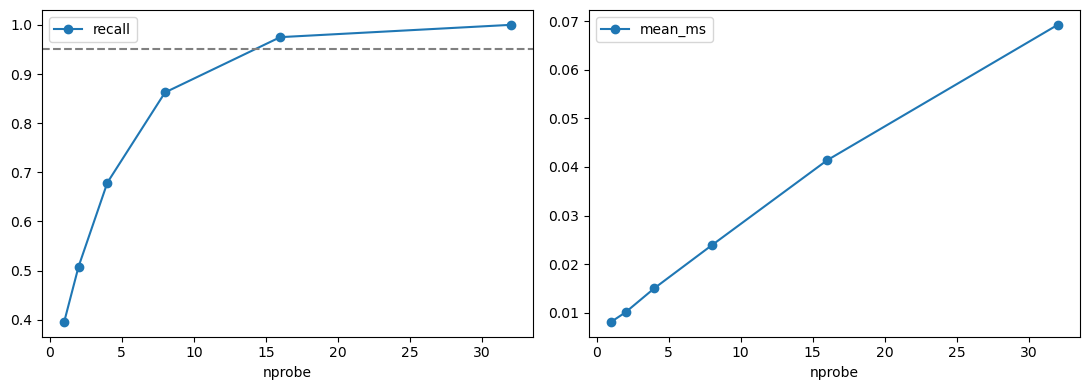

In [7]:
ivf_results = []
for nprobe in [1, 2, 4, 8, 16, 32]:
    ivf.nprobe = nprobe
    _, ids = ivf.search(q, k)
    ivf_results.append(dict(nprobe=nprobe, recall=ann_recall(ids, exact_ids).mean(), **measure_search(ivf)))
ivf_table = pd.DataFrame(ivf_results)
best_nprobe = int(ivf_table.loc[ivf_table.recall >= 0.95, "nprobe"].min())
ivf.nprobe = best_nprobe
ivf_scores, ivf_ids = ivf.search(q, k)
display(ivf_table.round(4))
print("Выбранный nprobe:", best_nprobe)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ivf_table.plot(x="nprobe", y="recall", marker="o", ax=axes[0])
axes[0].axhline(0.95, linestyle="--", color="gray")
ivf_table.plot(x="nprobe", y="mean_ms", marker="o", ax=axes[1])
plt.tight_layout()
plt.show()


## 8. Качество, поиск и стоимость построения

,ann_recall,document_recall,document_hit,build_seconds,mean_ms,p95_ms
method,,,,,,
Flat,1.0000,0.65764,0.875,0.00015,0.06135,0.07372
HNSW,0.9625,0.64722,0.875,0.20279,0.02286,0.02892
IVF,0.9750,0.67847,0.875,0.00902,0.04106,0.05295


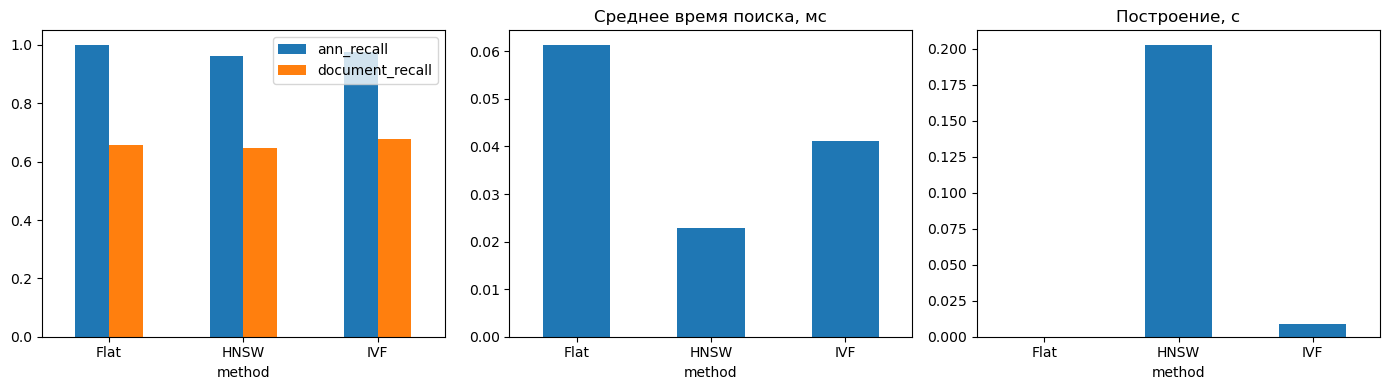

In [8]:
def build_index(method, vectors, ef=best_ef, nprobe=best_nprobe):
    dimension = vectors.shape[1]
    if method == "Flat":
        index = faiss.IndexFlatIP(dimension)
    elif method == "HNSW":
        index = faiss.IndexHNSWFlat(dimension, 16, faiss.METRIC_INNER_PRODUCT)
        index.hnsw.efConstruction = 200
        index.hnsw.efSearch = ef
    else:
        nlist = min(32, len(vectors) // 40)
        index = faiss.IndexIVFFlat(faiss.IndexFlatIP(dimension), dimension, nlist, faiss.METRIC_INNER_PRODUCT)
        index.cp.seed = 42
        index.train(vectors)
        index.nprobe = min(nprobe, nlist)
    index.add(vectors)
    return index

rows = []
indices = {"Flat": flat, "HNSW": hnsw, "IVF": ivf}
for method, index in indices.items():
    build_times = []
    for _ in range(3):
        start = perf_counter()
        rebuilt = build_index(method, x)
        build_times.append(perf_counter() - start)
        del rebuilt
    scores, ids = index.search(q, k)
    doc_recall, doc_hit = document_metrics(ids)
    rows.append(dict(method=method, ann_recall=ann_recall(ids, exact_ids).mean(),
                     document_recall=doc_recall, document_hit=doc_hit,
                     build_seconds=np.median(build_times), **measure_search(index)))
summary = pd.DataFrame(rows).set_index("method")
display(summary.round(5))
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
summary[["ann_recall", "document_recall"]].plot.bar(ax=axes[0], ylim=(0, 1.05), rot=0)
summary.mean_ms.plot.bar(ax=axes[1], title="Среднее время поиска, мс", rot=0)
summary.build_seconds.plot.bar(ax=axes[2], title="Построение, с", rot=0)
plt.tight_layout()
plt.show()


## 9. Когда окупается индекс

,method,requests_to_break_even
0,HNSW,5264
1,IVF,438


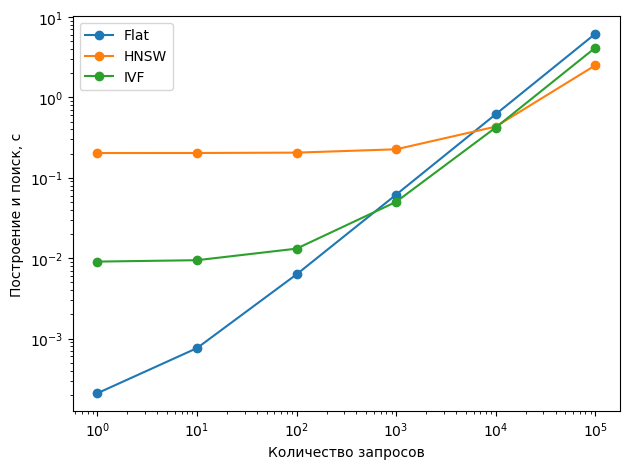

In [9]:
break_even = []
for method in ["HNSW", "IVF"]:
    saved_seconds = (summary.loc["Flat", "mean_ms"] - summary.loc[method, "mean_ms"]) / 1000
    extra_build = summary.loc[method, "build_seconds"] - summary.loc["Flat", "build_seconds"]
    count = max(0, int(np.ceil(extra_build / saved_seconds))) if saved_seconds > 0 else None
    break_even.append(dict(method=method, requests_to_break_even=count))
display(pd.DataFrame(break_even))
request_counts = np.array([1, 10, 100, 1000, 10000, 100000])
for method, row in summary.iterrows():
    total = row.build_seconds + request_counts * row.mean_ms / 1000
    plt.plot(request_counts, total, marker="o", label=method)
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Количество запросов")
plt.ylabel("Построение и поиск, с")
plt.legend()
plt.tight_layout()
plt.show()


## 10. Различия выдачи и релевантность

In [10]:
per_query = pd.DataFrame({"query_id": [item["query_id"] for item in queries], "query": [item["query"] for item in queries]})
search_results = {}
for method, index in indices.items():
    scores, ids = index.search(q, k)
    search_results[method] = (scores, ids)
    per_query[method + " ANN Recall@10"] = ann_recall(ids, exact_ids)
    per_query[method + " document recall"] = [
        len(set(chunks.iloc[row[row >= 0]].doc_id) & set(query["relevant"])) / len(query["relevant"])
        for query, row in zip(queries, ids)
    ]
display(per_query)
interesting = list(dict.fromkeys(
    per_query.nsmallest(2, "HNSW ANN Recall@10").index.tolist() +
    (per_query["IVF document recall"] - per_query["Flat document recall"]).abs().nlargest(2).index.tolist()
))
for i in interesting:
    for method, (scores, ids) in search_results.items():
        print(method)
        show_search(i, ids, scores)


,query_id,query,Flat ANN Recall@10,Flat document recall,HNSW ANN Recall@10,HNSW document recall,IVF ANN Recall@10,IVF document recall
0,q01,Как записать загрузку GPU в файл во время обуч...,1.0,1.000000,1.0,1.000000,1.0,1.000000
1,q02,"Почему одни машины в списке запускаются сразу,...",1.0,1.000000,0.9,1.000000,1.0,1.000000
2,q03,Можно ли перейти на другую вычислительную маши...,1.0,1.000000,0.8,1.000000,1.0,1.000000
3,q04,Какие конфигурации предлагают GPU A100 и сколь...,1.0,1.000000,0.9,1.000000,1.0,1.000000
4,q05,В ноутбуке не хватает библиотеки для графиков....,1.0,0.000000,1.0,0.000000,1.0,0.000000
5,q06,Проекту нужна другая версия Python: как перекл...,1.0,1.000000,1.0,1.000000,1.0,1.000000
6,q07,Как создать и активировать собственный Docker-...,1.0,1.000000,1.0,1.000000,1.0,1.000000
7,q08,"Как отправить скрипт на удалённое обучение, чт...",1.0,0.500000,0.7,0.250000,0.9,0.500000
8,q09,Хочу видеть бакет S3 как папку в JupyterLab и ...,1.0,1.000000,1.0,1.000000,1.0,1.000000
9,q10,Как использовать секрет в Python через перемен...,1.0,1.000000,1.0,1.000000,1.0,1.000000


Flat
Как отправить скрипт на удалённое обучение, чтобы сервис сам собрал его зависимости?


,rank,title,score,relevant
0,1,Установить зависимости,0.855462,False
1,2,Специальные условия для образовательных учрежд...,0.853069,False
2,3,Работа с секретами,0.850482,False
3,4,Среда исполнения заданий,0.849014,True
4,5,Добавить пользователя в проект,0.848849,False
5,6,Настроить окружение для развертывания самостоя...,0.848255,False
6,7,Развертывание сервиса на основе Docker-образа,0.847697,False
7,8,Работа с секретами,0.846738,False
8,9,Хранение приватных данных,0.846694,False
9,10,Запуск заданий DataSphere Jobs,0.846373,True


HNSW
Как отправить скрипт на удалённое обучение, чтобы сервис сам собрал его зависимости?


,rank,title,score,relevant
0,1,Установить зависимости,0.855462,False
1,2,Специальные условия для образовательных учрежд...,0.853069,False
2,3,Работа с секретами,0.850482,False
3,4,Добавить пользователя в проект,0.848849,False
4,5,Работа с секретами,0.846738,False
5,6,Хранение приватных данных,0.846693,False
6,7,Запуск заданий DataSphere Jobs,0.846373,True
7,8,Создание сервера MLFlow для логирования экспер...,0.845721,False
8,9,Работа с Git,0.845402,False
9,10,Удалить пользователя из проекта,0.845350,False


IVF
Как отправить скрипт на удалённое обучение, чтобы сервис сам собрал его зависимости?


... (15 outputs left out)

HNSW
Как записать загрузку GPU в файл во время обучения через nvidia-smi?


,rank,title,score,relevant
0,1,Проверить загрузку GPU,0.921893,True
1,2,Проверить загрузку GPU,0.907114,True
2,3,Проверить загрузку GPU,0.899537,True
3,4,Проверить загрузку GPU,0.894306,True
4,5,Проверить загрузку GPU,0.892104,True
5,6,Проверить загрузку GPU,0.889678,True
6,7,Проверить загрузку GPU,0.877864,True
7,8,Проверить загрузку GPU,0.866123,True
8,9,Проверить загрузку GPU,0.865350,True
9,10,Среда исполнения заданий,0.864341,False


IVF
Как записать загрузку GPU в файл во время обучения через nvidia-smi?


,rank,title,score,relevant
0,1,Проверить загрузку GPU,0.921893,True
1,2,Проверить загрузку GPU,0.907114,True
2,3,Проверить загрузку GPU,0.899537,True
3,4,Проверить загрузку GPU,0.894306,True
4,5,Проверить загрузку GPU,0.892104,True
5,6,Проверить загрузку GPU,0.889678,True
6,7,Проверить загрузку GPU,0.877864,True
7,8,Проверить загрузку GPU,0.866123,True
8,9,Проверить загрузку GPU,0.865350,True
9,10,Среда исполнения заданий,0.864341,False


## 11. Размер коллекции

,size,method,ann_recall,build_seconds,nlist,nprobe,mean_ms,p95_ms
0,250,Flat,1.00000,0.00004,NaN,NaN,0.01119,0.01150
1,250,HNSW,0.98333,0.00904,NaN,NaN,0.01551,0.01859
2,250,IVF,1.00000,0.00072,6.0,6.0,0.01427,0.01605
3,500,Flat,1.00000,0.00007,NaN,NaN,0.01911,0.02306
4,500,HNSW,0.97083,0.02935,NaN,NaN,0.01836,0.02291
5,500,IVF,1.00000,0.00150,12.0,12.0,0.02260,0.02765
6,1000,Flat,1.00000,0.00015,NaN,NaN,0.03284,0.04020
7,1000,HNSW,0.92917,0.07779,NaN,NaN,0.02181,0.02761
8,1000,IVF,0.97083,0.00452,25.0,16.0,0.02999,0.03951
9,2003,Flat,1.00000,0.00039,NaN,NaN,0.06344,0.07970


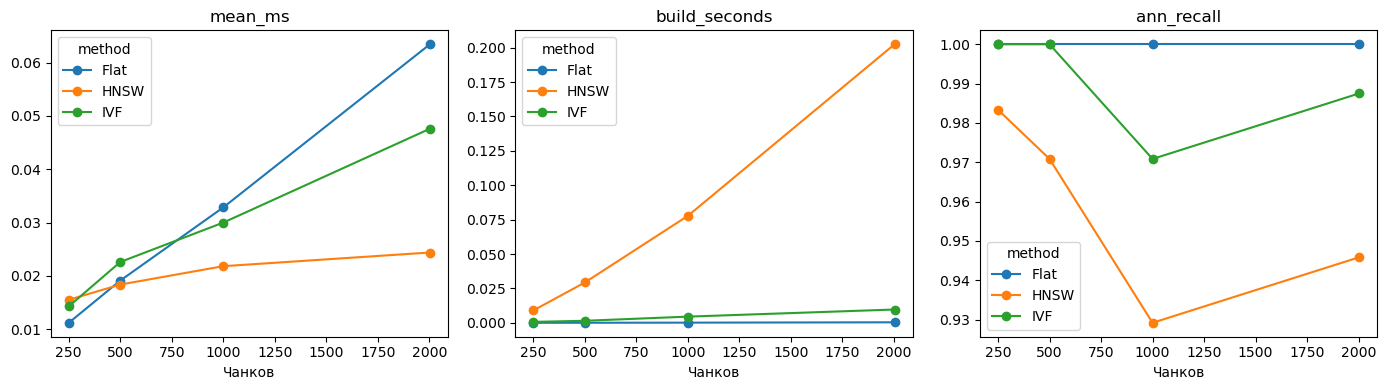

In [11]:
order = np.random.default_rng(42).permutation(len(x))
scaling_rows = []
for size in [250, 500, 1000, len(x)]:
    subset = np.ascontiguousarray(x[order[:size]])
    reference = build_index("Flat", subset)
    _, expected = reference.search(q, k)
    for method in ["Flat", "HNSW", "IVF"]:
        build_times = []
        for _ in range(3):
            start = perf_counter()
            index = build_index(method, subset)
            build_times.append(perf_counter() - start)
        _, found = index.search(q, k)
        scaling_rows.append(dict(size=size, method=method,
                                 ann_recall=ann_recall(found, expected).mean(),
                                 build_seconds=np.median(build_times),
                                 nlist=index.nlist if method == "IVF" else None,
                                 nprobe=index.nprobe if method == "IVF" else None,
                                 **measure_search(index)))
scaling = pd.DataFrame(scaling_rows)
display(scaling.round(5))
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for metric, ax in zip(["mean_ms", "build_seconds", "ann_recall"], axes):
    scaling.pivot(index="size", columns="method", values=metric).plot(marker="o", ax=ax, title=metric)
    ax.set_xlabel("Чанков")
plt.tight_layout()
plt.show()


## 12. Сохранение результатов

In [12]:
RESULTS = Path("results")
RESULTS.mkdir(exist_ok=True)
summary.to_csv(RESULTS / "comparison.csv")
hnsw_table.to_csv(RESULTS / "hnsw_parameters.csv", index=False)
ivf_table.to_csv(RESULTS / "ivf_parameters.csv", index=False)
per_query.to_csv(RESULTS / "per_query.csv", index=False)
scaling.to_csv(RESULTS / "scaling.csv", index=False)
pd.DataFrame(break_even).to_csv(RESULTS / "break_even.csv", index=False)
settings = dict(k=k, dimensions=x.shape[1], chunks=len(x), queries=len(q),
                faiss_version=faiss.__version__, threads=faiss.omp_get_max_threads(),
                M=16, efConstruction=200, efSearch=best_ef, nlist=32, nprobe=best_nprobe,
                query_repeats=100, build_repeats=3)
(RESULTS / "settings.json").write_text(json.dumps(settings, ensure_ascii=False, indent=2), encoding="utf-8")
display(summary.round(5))
print(settings)


,ann_recall,document_recall,document_hit,build_seconds,mean_ms,p95_ms
method,,,,,,
Flat,1.0000,0.65764,0.875,0.00015,0.06135,0.07372
HNSW,0.9625,0.64722,0.875,0.20279,0.02286,0.02892
IVF,0.9750,0.67847,0.875,0.00902,0.04106,0.05295


{'k': 10, 'dimensions': 384, 'chunks': 2003, 'queries': 24, 'faiss_version': '1.12.0', 'threads': 1, 'M': 16, 'efConstruction': 200, 'efSearch': 24, 'nlist': 32, 'nprobe': 16, 'query_repeats': 100, 'build_repeats': 3}
